# BMMC T2 | Cross-omics Prediction Figures

**目标：** 基于 ATLAS 旧版 `results/table2/BMMC` 下每个 `pair_XXX/predictions.npz`，绘制参考图 Figure 3b 的两张**分开保存**的图片：

- **True RNA vs Predicted RNA**：浅蓝散点、粉色 `y=x` 虚线，以及 Pearson / RMSE 指标框。
- **Prediction Error**：绝对误差 $|\hat{x}_{RNA}-x_{RNA}|$ 的浅蓝小提琴分布，叠加浅蓝散点，粉色中位数圆点。

分别输出 0%、20%、40%、60%、80%、100% 六种 paired ratio 的 PNG + PDF，**每种比例两张独立图片**。结果文件只读取，不修改任何模型、NPZ 或指标。

> 注意：右图是误差小提琴图叠加散点，**不是误差随 index 变化的散点图**。图中的表达量单位来自你现有的 `true_rna` / `pred_rna`，并不自动等价于原始整数 counts。

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'axes.labelsize': 14,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.unicode_minus': False,
})

# 参考图片中的浅蓝色 + 紫粉色
BLUE_DOTS = '#87AEFF'
BLUE_EDGE = '#7CA8FA'
BLUE_FILL = '#BCD6FF'
PINK = '#C42B91'
GRID = '#D7E8FF'
INK = '#333333'

## 1. 配置输入与输出目录

默认读取你发来的路径。配对比例按 `pair_000` → `pair_100` 的文件夹名称遍历。

- `SCATTER_RANGE=(0,3)`：与参考图保持一致的 True/Predicted RNA 坐标轴范围，完整指标不会因此被截取。
- `ERROR_YMAX_MIN=1.75`：误差图纵轴上限至少为 1.75；尾部较长时自动扩展，避免误差点被大量裁剪。
- 绘图抽样不参与 Pearson/RMSE 的重新计算，标注优先来自同目录的 `metrics.json`。

In [2]:
# ===== 改这里即可 =====
RESULT_ROOT = Path('/data5/zhangye/ATLAS/results/table2/BMMC')
OUTPUT_ROOT = RESULT_ROOT / 'visualizations' / 'T2_reference_style'

PAIRED_RATIOS = [0, 20, 40, 60, 80, 100]

SCATTER_MAX_POINTS = 12000     # 用于左图；按同一单元的真实RNA/预测RNA配对抽样
ERROR_DENSITY_MAX = 15000      # 用于小提琴 KDE
ERROR_DOTS_MAX = 5000          # 用于叠加到小提琴上的散点
RANDOM_SEED = 1234

SCATTER_RANGE = (0.0, 3.0)    # 想自动确定范围可改为 None
ERROR_YMAX_MIN = 1.75         # 尽量接近参考图的 0-1.7 范围，必要时会扩展
EXPORT_FORMATS = ('png', 'pdf')  # 可改成 ('png',) 以加快保存
DPI = 300

SCATTER_DIR = OUTPUT_ROOT / 'A_predicted_vs_true_RNA'
ERROR_DIR = OUTPUT_ROOT / 'B_prediction_error_violin'
SCATTER_DIR.mkdir(parents=True, exist_ok=True)
ERROR_DIR.mkdir(parents=True, exist_ok=True)

print('Reading:', RESULT_ROOT)
print('Saving:', OUTPUT_ROOT)

Reading: /data5/zhangye/ATLAS/results/table2/BMMC
Saving: /data5/zhangye/ATLAS/results/table2/BMMC/visualizations/T2_reference_style


## 2. 检查所有比例的预测文件及数组结构

需要读取 `predictions.npz` 中的 `true_rna` 和 `pred_rna`。只读取 `metrics.json` 作为可视化标注来源：`T2.Pearson`（**细胞级相关系数的均值**）与 `T2.RMSE`。这些指标和所有表达元素摊平后的 Pearson 不是同一种统计口径，不应混淆。

In [3]:
def run_folder(ratio):
    return RESULT_ROOT / f'pair_{ratio:03d}'


def inspect_pair(ratio):
    run = run_folder(ratio)
    npz_path = run / 'predictions.npz'
    metrics_path = run / 'metrics.json'
    print(f'\n=== paired={ratio:3d}% : {run} ===')
    if not npz_path.is_file():
        print('  MISSING:', npz_path)
        return False
    with np.load(npz_path, allow_pickle=False) as z:
        print('  NPZ arrays:')
        for key in z.files:
            arr = z[key]
            print(f'    {key:20s} shape={str(arr.shape):17s} dtype={arr.dtype}')
        if not {'true_rna', 'pred_rna'}.issubset(set(z.files)):
            raise KeyError(f'Missing true_rna or pred_rna in {npz_path}')
        if z['true_rna'].shape != z['pred_rna'].shape:
            raise ValueError(f'RNA shape mismatch in {npz_path}')
    if metrics_path.is_file():
        m = json.loads(metrics_path.read_text(encoding='utf-8'))
        print('  Stored T2 metrics:', m.get('T2', {}))
    else:
        print('  metrics.json not found; annotation will be calculated from NPZ.')
    return True

available = {ratio: inspect_pair(ratio) for ratio in PAIRED_RATIOS}
missing = [r for r, ok in available.items() if not ok]
if missing:
    print('\nSome ratios are missing:', missing)
else:
    print('\nAll six prediction NPZ files were found.')


=== paired=  0% : /data5/zhangye/ATLAS/results/table2/BMMC/pair_000 ===
  NPZ arrays:
    cell_ids             shape=(5161,)           dtype=<U25
    z_atac               shape=(5161, 32)        dtype=float32
    z_rna                shape=(5161, 32)        dtype=float32
    h_fused              shape=(5161, 32)        dtype=float32
    pred_rna             shape=(5161, 12093)     dtype=float32
    true_rna             shape=(5161, 12093)     dtype=float32
    t1_true_pca          shape=(5161, 30)        dtype=float64
    t1_pred_pca          shape=(5161, 30)        dtype=float64
    time                 shape=(5161,)           dtype=float32
    labels               shape=(5161,)           dtype=<U19
  Stored T2 metrics: {'Pearson': 0.43015866573684886, 'Pearson_cell': 0.43015866573684886, 'Pearson_gene': -0.030204008532601974, 'RMSE': 0.2234346481283103}

=== paired= 20% : /data5/zhangye/ATLAS/results/table2/BMMC/pair_020 ===
  NPZ arrays:
    cell_ids             shape=(6191,)      

## 3. 数据加载与统计函数

为了降低服务器绘图内存占用，散点图和小提琴图会对 **RNA 矩阵元素（cell × gene）** 分别随机采样。采样时同一个索引始终同时取真实值和预测值，防止破坏对应关系。

**Pearson 优先显示已有实验 `metrics.json` 的 T2 Pearson（通常 ×100 显示）；RMSE 亦使用实验原指标。** 如缺少原指标，将从全部有限数值中计算 RMSE 及平均细胞 Pearson，并提示来源。

In [4]:
def load_prediction(ratio):
    folder = run_folder(ratio)
    with np.load(folder / 'predictions.npz', allow_pickle=False) as z:
        if 'true_rna' not in z or 'pred_rna' not in z:
            raise KeyError(f'{folder}/predictions.npz lacks true_rna / pred_rna')
        true = np.asarray(z['true_rna'])
        pred = np.asarray(z['pred_rna'])
        ids = np.asarray(z['cell_ids']) if 'cell_ids' in z else None
    if true.ndim != 2 or pred.ndim != 2 or true.shape != pred.shape:
        raise ValueError(f'Expected identical [N_cells, N_genes], got {true.shape} vs {pred.shape}')
    if ids is not None and len(ids) != true.shape[0]:
        raise ValueError('cell_ids are not aligned with RNA matrix rows')
    if true.size == 0:
        raise ValueError('Empty RNA matrices')
    metrics_path = folder / 'metrics.json'
    metrics = json.loads(metrics_path.read_text(encoding='utf-8')) if metrics_path.exists() else {}
    return true, pred, metrics


def reference_metrics(true, pred, metrics):
    t2 = metrics.get('T2', {})
    pearson = t2.get('Pearson', t2.get('Pearson_cell'))
    rmse = t2.get('RMSE')
    source = 'metrics.json'
    if pearson is None:
        # Mean Pearson across cells, not flattened Pearson across all entries.
        corr = []
        for i in range(len(true)):
            y, p = np.asarray(true[i], float), np.asarray(pred[i], float)
            good = np.isfinite(y) & np.isfinite(p)
            if good.sum() > 2 and np.std(y[good]) > 1e-12 and np.std(p[good]) > 1e-12:
                corr.append(np.corrcoef(y[good], p[good])[0, 1])
        pearson = np.mean(corr) if corr else np.nan
        source = 'computed from all cells (fallback)'
    if rmse is None:
        sse, n = 0.0, 0
        for i in range(len(true)):
            y, p = np.asarray(true[i], float), np.asarray(pred[i], float)
            good = np.isfinite(y) & np.isfinite(p)
            d = p[good] - y[good]
            sse += float(np.dot(d, d))
            n += int(good.sum())
        rmse = np.sqrt(sse / n) if n else np.nan
        source = 'partly computed from all elements (fallback)'
    pearson = float(pearson)
    pearson_display = pearson * 100 if -1.0 <= pearson <= 1.0 else pearson
    return pearson_display, float(rmse), source


def sample_corresponding_entries(true, pred, max_points, seed):
    """Uniform paired sampling of matrix elements, preserving true/pred alignment."""
    if true.shape != pred.shape:
        raise ValueError('Shapes must match')
    n_total = true.size
    rng = np.random.default_rng(seed)
    n_sample = min(int(max_points), n_total)
    if n_sample == n_total:
        ids = np.arange(n_total)
    else:
        ids = rng.choice(n_total, size=n_sample, replace=False)
    y = np.asarray(true).ravel()[ids].astype(np.float64, copy=False)
    p = np.asarray(pred).ravel()[ids].astype(np.float64, copy=False)
    good = np.isfinite(y) & np.isfinite(p)
    return y[good], p[good]


def format_axes(ax):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#6A6A6A')
    ax.spines['bottom'].set_color('#6A6A6A')
    ax.spines['left'].set_linewidth(1.0)
    ax.spines['bottom'].set_linewidth(1.0)
    ax.tick_params(direction='out', color='#777777', length=3)
    ax.grid(True, color=GRID, alpha=0.7, linewidth=0.65)
    ax.set_axisbelow(True)


def save_figure(fig, path_without_suffix):
    created = []
    for extension in EXPORT_FORMATS:
        output = path_without_suffix.with_suffix('.' + extension)
        fig.savefig(output, bbox_inches='tight', dpi=DPI, facecolor='white')
        created.append(output)
    return created

## 4. 左图：Predicted RNA vs True RNA（单独保存）

- 淡蓝色散点：随机抽取的**配对** RNA 表达元素。
- 粉色虚线：理想预测 $y=x$。
- 左上角指标框：同一 run 的 T2 Pearson（×100）与 RMSE。
- 图的真实数据不进行裁剪；仅图像显示范围默认固定为 0–3。若数据超出该范围，控制台会输出抽样点的范围外比例。

In [34]:
def plot_prediction_scatter(ratio, true, pred, metrics, *, save=True, show=True):
    yt, yp = sample_corresponding_entries(
        true, pred, SCATTER_MAX_POINTS, seed=RANDOM_SEED + 1000 + int(ratio)
    )
    if yt.size == 0:
        raise ValueError(f'No finite scatter points for ratio {ratio}')
    pearson, rmse, source = reference_metrics(true, pred, metrics)

    if SCATTER_RANGE is None:
        arr = np.concatenate([yt, yp])
        lo = min(0.0, float(np.quantile(arr, 0.003)))
        hi = float(np.quantile(arr, 0.997))
        hi = max(hi, lo + 0.5)
    else:
        lo, hi = SCATTER_RANGE

    fig, ax = plt.subplots(figsize=(4.9, 4.65))
    ax.scatter(yt, yp, s=4.2, c=BLUE_DOTS, alpha=0.48, linewidths=0, rasterized=True)
    ax.plot([lo, hi], [lo, hi], color=PINK, linewidth=1.55, linestyle='--', zorder=5)
    ax.set_xlim(lo, 2.0)
    ax.set_ylim(lo, 2.0)
    ax.set_box_aspect(1)
    ax.set_xlabel('True RNA')
    ax.set_ylabel('Predicted RNA')
    format_axes(ax)
    if SCATTER_RANGE == (0.0, 3.0):
        ax.xaxis.set_major_locator(MultipleLocator(1.0))
        ax.yaxis.set_major_locator(MultipleLocator(1.0))

    # ax.text(
    #     0.045, 0.965, f'Pearson = {pearson:.1f}\nRMSE = {rmse:.3f}',
    #     transform=ax.transAxes, va='top', ha='left', fontsize=12,
    #     color=INK,
    #     bbox={'boxstyle': 'round,pad=0.32',
    #           'facecolor': '#E6EEF9', 'edgecolor': '#A8ABB1',
    #           'linewidth': 1.0, 'alpha': 0.95},
    # )

    n_off_plot = int(np.count_nonzero((yt < lo) | (yt > hi) | (yp < lo) | (yp > hi)))
    percentage_outside = 100 * n_off_plot / max(len(yt), 1)
    name = SCATTER_DIR / f'BMMC_T2_RNA_scatter_pair_wotext_{ratio:03d}'
    paths = save_figure(fig, name) if save else []
    if show:
        plt.show()
    plt.close(fig)
    print(f'paired={ratio:3d}% | scatter={len(yt):,} | outside view={percentage_outside:.2f}% | '
          f'Pearson={pearson:.2f} RMSE={rmse:.4f} ({source})')
    for path in paths:
        print('  Saved:', path)
    return {
        'ratio': ratio, 'Pearson_display': pearson, 'RMSE': rmse,
        'scatter_points': len(yt), 'scatter_pct_outside_view': percentage_outside,
        'metric_source': source,
    }

## 5. 右图：Prediction Error 的小提琴图 + 蓝色散点（单独保存）

定义每个真实/预测 RNA **相同 cell、相同 gene 元素**的绝对误差：

$$e_{ij}=|\hat{x}_{ij}-x_{ij}|.$$

- **小提琴的宽度**代表绝对误差的经验密度。
- **散点**是这些误差的随机子样本，加入很小的横向 jitter，模拟参考图中竖直的蓝色点云。
- **粉色圆点**表示误差的中位数；误差图和散点预测图**分文件保存**。

> 注：`RMSE` 为均方根误差，而右图展示的是逐元素绝对误差，它们不是同一个量。绘图不根据图上点重新计算已存储的 T2 RMSE。

In [35]:
def plot_prediction_error_violin(ratio, true, pred, *, save=True, show=True):
    y_density, p_density = sample_corresponding_entries(
        true, pred, ERROR_DENSITY_MAX, seed=RANDOM_SEED + 2000 + int(ratio)
    )
    y_dot, p_dot = sample_corresponding_entries(
        true, pred, ERROR_DOTS_MAX, seed=RANDOM_SEED + 3000 + int(ratio)
    )
    density_err = np.abs(p_density - y_density)
    dot_err = np.abs(p_dot - y_dot)
    if density_err.size < 3:
        raise ValueError(f'Not enough finite RNA errors for ratio {ratio}')

    fig, ax = plt.subplots(figsize=(2.75, 4.65))
    parts = ax.violinplot(
        [density_err], positions=[1], widths=0.78,
        showmeans=False, showmedians=False, showextrema=False,
        bw_method=0.13,
    )
    for body in parts['bodies']:
        body.set_facecolor(BLUE_FILL)
        body.set_edgecolor(BLUE_EDGE)
        body.set_linewidth(1.1)
        body.set_alpha(0.63)

    rng = np.random.default_rng(RANDOM_SEED + 4000 + int(ratio))
    jitter = rng.normal(loc=0.0, scale=0.018, size=len(dot_err))
    ax.scatter(
        1 + jitter, dot_err, s=2.2,
        c=BLUE_DOTS, alpha=0.24, linewidths=0, rasterized=True, zorder=3,
    )
    median_abs_error = float(np.median(density_err))
    ax.scatter([1], [median_abs_error], s=30, color=PINK,
               edgecolor='white', linewidth=0.65, zorder=6)

    # 参考图以 ~1.7 为纵轴上限；如果真实误差尾部更长则自动扩大。
    upper = max(float(ERROR_YMAX_MIN), float(np.quantile(density_err, 0.999) * 1.08))
    ax.set_ylim(0.0, upper)
    ax.set_xlim(0.50, 1.50)
    ax.set_xticks([1])
    ax.set_xticklabels([f'Ratio={ratio}'])
    ax.set_ylabel('Prediction Error')
    format_axes(ax)
    ax.grid(axis='y', color=GRID, alpha=0.80, linewidth=0.72)
    ax.grid(axis='x', visible=False)

    name = ERROR_DIR / f'BMMC_T2_error_violin_pair_{ratio:03d}'
    paths = save_figure(fig, name) if save else []
    if show:
        plt.show()
    plt.close(fig)
    fraction_clipped = 100 * float(np.mean(dot_err > upper))
    print(f'paired={ratio:3d}% | violin_n={len(density_err):,}, dots_n={len(dot_err):,} '
          f'| median |error|={median_abs_error:.4f} | displayed dot clip={fraction_clipped:.2f}%')
    for path in paths:
        print('  Saved:', path)
    return {
        'ratio': ratio, 'median_abs_error_sample': median_abs_error,
        'violin_points': len(density_err), 'violin_dots': len(dot_err),
        'error_ymax': upper, 'error_pct_outside_view': fraction_clipped,
    }

## 6. 先单独预览配对比例 20% 的两张图

先逐格运行这段，确认散点图、误差小提琴图都符合预期。此时先显示，不写文件。

True RNA: (6191, 12093) float32
Pred RNA: (6191, 12093) float32


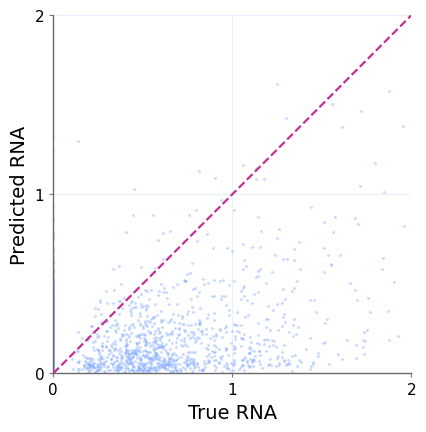

paired= 20% | scatter=12,000 | outside view=1.97% | Pearson=52.68 RMSE=0.2099 (metrics.json)


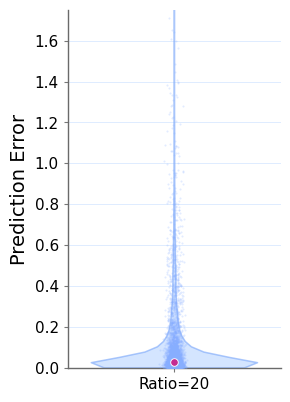

paired= 20% | violin_n=15,000, dots_n=5,000 | median |error|=0.0290 | displayed dot clip=0.02%


In [36]:
PREVIEW_RATIO = 20
true_rna, pred_rna, metrics = load_prediction(PREVIEW_RATIO)
print('True RNA:', true_rna.shape, true_rna.dtype)
print('Pred RNA:', pred_rna.shape, pred_rna.dtype)

_ = plot_prediction_scatter(
    PREVIEW_RATIO, true_rna, pred_rna, metrics, save=False, show=True
)
_ = plot_prediction_error_violin(
    PREVIEW_RATIO, true_rna, pred_rna, save=False, show=True
)

## 7. 批量生成 0%–100% 的所有图片

下面会遍历每个 `pair_XXX`。对每个比例分别保存：

- `A_predicted_vs_true_RNA/BMMC_T2_RNA_scatter_pair_XXX.png`（以及 PDF）
- `B_prediction_error_violin/BMMC_T2_error_violin_pair_XXX.png`（以及 PDF）

共 **6 × 2 = 12 张独立图**（若 PNG + PDF 都保存，则有 24 个图片文件）。缺失目录时跳过并提示，其他异常直接报错便于定位。

In [37]:
scatter_rows = []
error_rows = []

for ratio in PAIRED_RATIOS:
    path = run_folder(ratio) / 'predictions.npz'
    if not path.is_file():
        warnings.warn(f'Skipped pair_{ratio:03d}: missing {path}')
        continue
    print(f'\n============ Processing BMMC paired {ratio}% ============')
    true_rna, pred_rna, metrics = load_prediction(ratio)
    scatter_rows.append(
        plot_prediction_scatter(ratio, true_rna, pred_rna, metrics, save=True, show=False)
    )
    error_rows.append(
        plot_prediction_error_violin(ratio, true_rna, pred_rna, save=True, show=False)
    )
    # Arrays intentionally discarded at the next iteration to save memory.

scatter_summary = pd.DataFrame(scatter_rows)
error_summary = pd.DataFrame(error_rows)
if not scatter_summary.empty:
    scatter_summary.merge(error_summary, on='ratio', how='left').to_csv(
        OUTPUT_ROOT / 'BMMC_T2_visualization_stats.csv', index=False
    )
print('\nFinished. Output folder:', OUTPUT_ROOT)
summary_table = scatter_summary.merge(error_summary, on='ratio', how='left')
print(summary_table.to_string(index=False))


============ Processing BMMC paired 0% ============
paired=  0% | scatter=12,000 | outside view=0.03% | Pearson=43.02 RMSE=0.2234 (metrics.json)
  Saved: /data5/zhangye/ATLAS/results/table2/BMMC/visualizations/T2_reference_style/A_predicted_vs_true_RNA/BMMC_T2_RNA_scatter_pair_wotext_000.png
  Saved: /data5/zhangye/ATLAS/results/table2/BMMC/visualizations/T2_reference_style/A_predicted_vs_true_RNA/BMMC_T2_RNA_scatter_pair_wotext_000.pdf
paired=  0% | violin_n=15,000, dots_n=5,000 | median |error|=0.0313 | displayed dot clip=0.10%
  Saved: /data5/zhangye/ATLAS/results/table2/BMMC/visualizations/T2_reference_style/B_prediction_error_violin/BMMC_T2_error_violin_pair_000.png
  Saved: /data5/zhangye/ATLAS/results/table2/BMMC/visualizations/T2_reference_style/B_prediction_error_violin/BMMC_T2_error_violin_pair_000.pdf

============ Processing BMMC paired 20% ============
paired= 20% | scatter=12,000 | outside view=1.97% | Pearson=52.68 RMSE=0.2099 (metrics.json)
  Saved: /data5/zhangye/ATLA

## 8. 查看文件清单与注意事项

这些图的纵横坐标、颜色和标题与参考图一致；两张单独保存，便于你在论文里重新组合排版。

1. **Pearson 的来源**：优先使用 `metrics.json → T2 → Pearson`，如 0.636 显示为 **63.6**；它是每个细胞维度相关系数的平均值，不是对散点采样元素重新计算的 Pearson。
2. **图上数据抽样**：仅为了渲染效率，**不会影响保存的实验指标**。采样使用固定随机种子。
3. **固定显示范围**：左图默认 `[0, 3] × [0, 3]`，超出的点只在显示时被裁剪；如果 `scatter_pct_outside_view` 很高，建议把 `SCATTER_RANGE` 改成 `None`。
4. **误差小提琴**：误差按 RNA 表达矩阵的每个元素计算；其分布与按细胞聚合的误差分布不同。误差轴会扩展以覆盖至少 99.9% 的抽样点。
5. **运行位置**：需使用包含 `numpy / pandas / matplotlib` 的 `scmrdr` Python 内核，并能够读取服务器 `/data5/zhangye/ATLAS` 路径。

In [38]:
print('RNA prediction scatter figures:')
for path in sorted(SCATTER_DIR.glob('*.png')):
    print('  ', path)

print('RNA error violin figures:')
for path in sorted(ERROR_DIR.glob('*.png')):
    print('  ', path)

RNA prediction scatter figures:
   /data5/zhangye/ATLAS/results/table2/BMMC/visualizations/T2_reference_style/A_predicted_vs_true_RNA/BMMC_T2_RNA_scatter_pair_000.png
   /data5/zhangye/ATLAS/results/table2/BMMC/visualizations/T2_reference_style/A_predicted_vs_true_RNA/BMMC_T2_RNA_scatter_pair_020.png
   /data5/zhangye/ATLAS/results/table2/BMMC/visualizations/T2_reference_style/A_predicted_vs_true_RNA/BMMC_T2_RNA_scatter_pair_040.png
   /data5/zhangye/ATLAS/results/table2/BMMC/visualizations/T2_reference_style/A_predicted_vs_true_RNA/BMMC_T2_RNA_scatter_pair_060.png
   /data5/zhangye/ATLAS/results/table2/BMMC/visualizations/T2_reference_style/A_predicted_vs_true_RNA/BMMC_T2_RNA_scatter_pair_080.png
   /data5/zhangye/ATLAS/results/table2/BMMC/visualizations/T2_reference_style/A_predicted_vs_true_RNA/BMMC_T2_RNA_scatter_pair_100.png
   /data5/zhangye/ATLAS/results/table2/BMMC/visualizations/T2_reference_style/A_predicted_vs_true_RNA/BMMC_T2_RNA_scatter_pair_wotext_000.png
   /data5/zhangy